# RECIPE GEOFISIKA TERMAL: VERIFIKASI SOLVER DIFUSI PANAS 1D TERHADAP SOLUSI ANALITIK (FTCS vs ERFC)

**Nama :** Zhafira Zahra **NIM :** H061251039
| Metadata Recipe | Spesifikasi |
| :--- | :--- |
| **Recipe ID** | `R-MOD-001` |
| **Prompt ID** | `P-MOD-001` |
| **Equation ID** | `E-HEAT-001` |
| **Kelompok Kerja** | `modeling` |
| **Tingkat Workflow** | Parameterized + Conditional Prompt (stability guard) dengan verifikasi 3 resolusi |
| **Status Bukti** | `Executed` pada 2026-10-20 23:42 UTC (21 Okt 2026 WIB), Python 3.13.16, Linux; semua check lulus. Kontrol negatif dan guard-trip juga dijalankan dan dicatat |
| **Referensi** | Metodologi *AI Cookbook untuk Earth Sciences*, Bab 2 (terutama 2.1, 2.2, 2.4, 2.5, 2.6) |

> **Jenis klaim recipe ini: verifikasi numerik**, yaitu apakah kode menyelesaikan persamaan dengan benar. Recipe ini **bukan validasi** terhadap data lapangan dan tidak mengklaim kalibrasi model ke borehole mana pun.

---

## 1. Problem dan Batas Keputusan

* **Pertanyaan ilmiah.** Jika permukaan tanah mendadak menghangat 10 K dan tetap demikian selama 100 tahun, bagaimana profil temperatur terhadap kedalaman pada medium homogen, dan seberapa akurat solver FTCS (*forward-time central-space*) saya mereproduksi solusi analitiknya?
* **Pengguna hasil.** Mahasiswa/peneliti geofisika yang akan memakai solver ini sebagai dasar tahap berikutnya (mis. inversi riwayat temperatur permukaan dari profil borehole).
* **Keputusan yang didukung.** Apakah solver ini layak dipakai sebagai *baseline* terverifikasi: stabil, galat di bawah toleransi, dan konvergen saat grid dihaluskan.
* **Satu outcome utama.** Tabel konvergensi + profil terverifikasi + run record. Recipe ini **tidak** mengerjakan inversi, kalibrasi, atau interpretasi paleoklimat.
* **Alasan dipecah dari recipe lain** (Bab 2.4.1 langkah 1): inversi riwayat temperatur punya risiko ilmiah dan acceptance rule berbeda, sehingga menjadi recipe terpisah yang memakai solver ini sebagai input terverifikasi.

---

## 2. Minimal Theory dan Asumsi (`E-HEAT-001`)

**Persamaan atur** (konduksi panas 1D, sumbu $z$ positif ke bawah, tanpa sumber panas):

$$\frac{\partial T}{\partial t} = \alpha \frac{\partial^2 T}{\partial z^2}$$

| Besaran | Nilai | Satuan |
| :--- | :---: | :---: |
| Difusivitas termal $\alpha$ | $1{,}0\times10^{-6}$ (orde batuan kristalin) | $\text{m}^2\,\text{s}^{-1}$ |
| Temperatur awal $T_0$ | 25 | °C |
| Temperatur permukaan setelah $t=0$, $T_s$ | 35 (loncatan +10 K) | °C |
| Waktu akhir | 100 | tahun (1 th = 365,25 hari) |
| Kedalaman domain $z_{max}$ | 1000 | m |

**Kondisi awal dan batas:** $T(z,0)=T_0$; $T(0,t)=T_s$ (Dirichlet); $T(z_{max},t)=T_0$ (Dirichlet, domain cukup dalam sehingga tidak terpengaruh).

**Solusi analitik half-space** (pembanding):

$$T(z,t)=T_0+(T_s-T_0)\,\operatorname{erfc}\!\left(\frac{z}{2\sqrt{\alpha t}}\right)$$

Kedalaman penetrasi karakteristik $2\sqrt{\alpha t}\approx 112$ m pada $t=100$ tahun.

**Skema numerik FTCS** dengan $r=\alpha\,\Delta t/\Delta z^2$:

$$T_i^{n+1}=T_i^n+r\,\left(T_{i+1}^n-2T_i^n+T_{i-1}^n\right)$$

* **Syarat stabilitas:** $r\le 1/2$.
* **Ekspektasi galat:** dengan $r$ dijaga konstan ($\Delta t\propto\Delta z^2$), galat pemotongan diperkirakan $O(\Delta z^2)$. Ini **hipotesis**; orde sebenarnya **diukur** dari data (bukan diasumsikan) pada bagian 7.
* **Pemeriksaan independen:** integral anomali panas $\int_0^{z_{max}}(T-T_0)\,dz \approx (T_s-T_0)\,2\sqrt{\alpha t/\pi}$, yang tidak bergantung pada perbandingan titik-demi-titik.

**Asumsi dan batas:** medium homogen, $\alpha$ konstan, tanpa panas radiogenik, tanpa adveksi fluida, perubahan permukaan berupa loncatan ideal. Hasil tidak dapat diekstrapolasi ke medium berlapis atau riwayat temperatur nyata tanpa recipe tambahan.

---

## 3. Input dan Constraint Contract

### Input
* **Konfigurasi:** `configurations/r-mod-001.json`, satu-satunya sumber parameter (tidak ada data eksternal, tidak ada jaringan).
* **Grid:** $\Delta z = 20,\ 10,\ 5$ m; $r_{target}=0{,}4$.
* **Input yang dilarang:** parameter yang ditulis ulang di dalam kode; hasil dari run lain.

### Constraints (dapat diuji lewat check atau `diff`)
1. Stability guard: bila $r>0{,}5$ pada grid mana pun, run **berhenti** dengan exit code 2 dan tidak ada output yang dipromosikan.
2. Tidak ada imputasi, tidak ada penyesuaian parameter agar hasil lulus.
3. Pustaka: `numpy`, `scipy.special`, `matplotlib`, dan standard library saja; tanpa jaringan.
4. Output baru ditulis ke `results/modeling/r-mod-001/<run_name>/`; run gagal ke `results/failed-runs/`. Tidak ada file lama yang ditimpa.
5. Toleransi **ditetapkan sebelum run** di dalam file konfigurasi (bukan disesuaikan setelah melihat hasil).

---

## 4. Reusable Prompt Specification (`P-MOD-001`)

Disusun mengikuti $P=\langle R,T,C,I,K,O,Q,V\rangle$ (Bab 2.1).

```text
[Role (R)]
Numerical-model implementation reviewer dan scientific Python developer. Peran ini dipakai untuk
menentukan prioritas (stabilitas, unit, batas, pembanding) dan BUKAN sebagai bukti kebenaran hasil.

[Task (T)]
Implementasikan difusi panas 1D skema FTCS untuk loncatan temperatur permukaan pada half-space,
jalankan pada tiga resolusi grid, bandingkan profil pada t akhir dengan solusi analitik erfc,
hitung galat maks, RMSE, orde konvergensi amatan, dan galat integral anomali panas.

[Context (C)]
Verifikasi numerik solver sebagai baseline sebelum dipakai pada recipe berikutnya. Output hanya
untuk verifikasi implementasi; jangan mengklaim kalibrasi, validasi lapangan, atau interpretasi
paleoklimat.

[Input (I)]
Hanya configurations/r-mod-001.json (alpha, T_initial, T_surface, t_end, zmax, dz, r_target,
toleransi). Unit: m, s, K/°C, tahun = 365,25 hari. z positif ke bawah. Tanpa jaringan.

[Constraints (K)]
1. Hentikan run (exit code 2) bila r = alpha*dt/dz^2 > 0,5; jangan menurunkan dt secara diam-diam.
2. Jangan mengubah parameter atau toleransi agar check lulus.
3. Pustaka: numpy, scipy.special, matplotlib, standard library.
4. Tulis ke direktori run baru; jangan menimpa output yang ada.

[Output (O)]
- results/modeling/r-mod-001/<run>/convergence.csv
- results/modeling/r-mod-001/<run>/profiles_dz5m.csv  (numerik, analitik, galat; t = 10, 50, 100 th)
- results/modeling/r-mod-001/<run>/summary.json
- figures/modeling/r-mod-001_<run>.png
- results/run-records/r-mod-001-<run>.json  (command, versi, SHA-256 input/kode/output, check, status)

[Quality Criteria (Q)]
Galat maks grid terhalus <= 0,05 K; galat menurun monoton saat grid dihaluskan; orde amatan >= 1,0;
galat relatif integral anomali <= 1%; semua nilai finite; T tetap di [T_initial, T_surface];
kebocoran batas bawah <= 1e-6 K.

[Verification (V)]
Rerun di direktori bersih dan bandingkan SHA-256 output; jalankan kontrol negatif (r > 0,5) untuk
membuktikan check memang dapat gagal. Pisahkan observasi, perhitungan, inferensi, dan batasan.
Label status mengikuti bukti: jangan menulis "Executed" tanpa run record.
```

---

## 5. Implementation

Struktur file mengikuti Bab 2.6.1: konfigurasi dipisahkan dari kode, dan kode menyimpan perilaku penting yang tidak dapat dipastikan dari prosa prompt. Sel berikut menulis file ke disk (`%%writefile`), lalu sel-sel run memanggil skrip dari shell.

In [1]:
%%writefile configurations/r-mod-001.json
{
  "run_name": "baseline",
  "run_kind": "baseline",
  "description": "Pemanasan permukaan tanah 10 K selama 100 tahun pada half-space homogen.",
  "alpha_m2_s": 1.0e-6,
  "T_initial_C": 25.0,
  "T_surface_C": 35.0,
  "t_end_yr": 100.0,
  "zmax_m": 1000.0,
  "dz_m": [20.0, 10.0, 5.0],
  "r_target": 0.4,
  "tolerances": {
    "max_abs_err_finest_K": 0.05,
    "min_observed_order": 1.0,
    "integral_rel_err": 0.01,
    "domain_leak_K": 1e-6
  }
}

Writing configurations/r-mod-001.json


In [2]:
%%writefile code/recipes/modeling/r-mod-001.py
"""
Recipe ID : R-MOD-001
Prompt ID : P-MOD-001
Equation  : E-HEAT-001  (1D heat diffusion, half-space dengan surface temperature step)

Difusi panas 1D (skema eksplisit FTCS) pada tiga resolusi grid, dibandingkan
dengan solusi analitik erfc. Menulis tabel, figure, dan run record.

Pemakaian:
    python code/recipes/modeling/r-mod-001.py --config configurations/r-mod-001.json

Exit code: 0 = selesai (lihat field "checks_all_passed" di run record),
           2 = dihentikan oleh stability guard (tidak ada output yang dipromosikan).
"""
import argparse
import datetime
import hashlib
import json
import os
import platform
import sys

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker
import numpy as np
import scipy
from scipy.special import erfc

SEC_PER_YEAR = 365.25 * 24 * 3600.0


class StabilityError(RuntimeError):
    pass


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 16), b""):
            h.update(chunk)
    return h.hexdigest()


def analytic(z, t, alpha, T0, Ts):
    """T(z,t) = T0 + (Ts - T0) * erfc(z / (2 sqrt(alpha t)))  [E-HEAT-001]"""
    return T0 + (Ts - T0) * erfc(z / (2.0 * np.sqrt(alpha * t)))


def run_ftcs(dz, cfg, bypass_guard=False):
    """Skema FTCS: T_i^{n+1} = T_i^n + r (T_{i+1}^n - 2 T_i^n + T_{i-1}^n)."""
    alpha, zmax = cfg["alpha_m2_s"], cfg["zmax_m"]
    T0, Ts = cfg["T_initial_C"], cfg["T_surface_C"]
    t_end = cfg["t_end_yr"] * SEC_PER_YEAR

    nz = int(round(zmax / dz))
    z = np.linspace(0.0, zmax, nz + 1)

    # n_steps dibulatkan ke kelipatan 10 supaya snapshot 10%, 50%, 100% jatuh tepat pada langkah waktu.
    dt_max = cfg["r_target"] * dz ** 2 / alpha
    n_steps = int(np.ceil(t_end / dt_max))
    n_steps = int(np.ceil(n_steps / 10.0) * 10)
    dt = t_end / n_steps
    r = alpha * dt / dz ** 2

    if r > 0.5 and not bypass_guard:
        raise StabilityError(
            f"dz={dz} m: r = alpha*dt/dz^2 = {r:.3f} > 0.5 (syarat stabilitas FTCS). Run dihentikan."
        )

    T = np.full(nz + 1, T0, dtype=float)
    T[0] = Ts
    snap_steps = {int(n_steps * f): f for f in (0.1, 0.5, 1.0)}
    snaps = {}
    for n in range(1, n_steps + 1):
        T[1:-1] = T[1:-1] + r * (T[2:] - 2.0 * T[1:-1] + T[:-2])
        T[0], T[-1] = Ts, T0
        if n in snap_steps:
            snaps[snap_steps[n]] = (n * dt, T.copy())
    return dict(dz=dz, z=z, dt=dt, n_steps=n_steps, r=r, snaps=snaps)


def evaluate(run, cfg):
    alpha = cfg["alpha_m2_s"]
    T0, Ts = cfg["T_initial_C"], cfg["T_surface_C"]
    t, T = run["snaps"][1.0]
    z = run["z"]
    err = T - analytic(z, t, alpha, T0, Ts)
    finite = bool(np.all(np.isfinite(T)))
    num_int = float(np.trapezoid(T - T0, z)) if finite else float("nan")
    ana_int = (Ts - T0) * 2.0 * np.sqrt(alpha * t / np.pi)
    return dict(
        dz_m=run["dz"], dt_s=run["dt"], n_steps=run["n_steps"], r=run["r"],
        max_abs_err_K=float(np.max(np.abs(err))) if finite else float("inf"),
        rmse_K=float(np.sqrt(np.mean(err ** 2))) if finite else float("inf"),
        T_min_C=float(np.min(T)), T_max_C=float(np.max(T)),
        integral_numeric_K_m=num_int, integral_analytic_K_m=float(ana_int),
        integral_rel_err=float(abs(num_int - ana_int) / ana_int) if finite else float("inf"),
        finite=finite,
    )


def add_orders(rows):
    for i, row in enumerate(rows):
        if i == 0:
            row["order_max"] = row["order_rmse"] = None
        else:
            prev = rows[i - 1]
            ratio = prev["dz_m"] / row["dz_m"]
            row["order_max"] = float(np.log(prev["max_abs_err_K"] / row["max_abs_err_K"]) / np.log(ratio))
            row["order_rmse"] = float(np.log(prev["rmse_K"] / row["rmse_K"]) / np.log(ratio))


def run_checks(rows, cfg):
    tol = cfg["tolerances"]
    T0, Ts = cfg["T_initial_C"], cfg["T_surface_C"]
    alpha, zmax = cfg["alpha_m2_s"], cfg["zmax_m"]
    t_end = cfg["t_end_yr"] * SEC_PER_YEAR
    finest = rows[-1]
    errs = [r["max_abs_err_K"] for r in rows]
    leak = (Ts - T0) * float(erfc(zmax / (2.0 * np.sqrt(alpha * t_end))))
    eps = 1e-9
    checks = [
        ("stability: r <= 0.5 pada semua grid", max(r["r"] for r in rows), "<= 0.5",
         all(r["r"] <= 0.5 for r in rows)),
        ("semua nilai finite", all(r["finite"] for r in rows), "True", all(r["finite"] for r in rows)),
        ("domain cukup dalam: kebocoran batas bawah (K)", leak, f"<= {tol['domain_leak_K']}",
         leak <= tol["domain_leak_K"]),
        ("maximum principle: T dalam [T_initial, T_surface]",
         [min(r["T_min_C"] for r in rows), max(r["T_max_C"] for r in rows)],
         f"[{T0}, {Ts}] +/- {eps}",
         all(r["T_min_C"] >= T0 - eps and r["T_max_C"] <= Ts + eps for r in rows)),
        ("galat maks menurun monoton saat grid dihaluskan", errs, "strictly decreasing",
         all(errs[i] > errs[i + 1] for i in range(len(errs) - 1))),
        ("galat maks grid terhalus (K)", finest["max_abs_err_K"], f"<= {tol['max_abs_err_finest_K']}",
         finest["max_abs_err_K"] <= tol["max_abs_err_finest_K"]),
        ("orde amatan (grid terhalus, norma maks)", finest["order_max"], f">= {tol['min_observed_order']}",
         finest["order_max"] is not None and finest["order_max"] >= tol["min_observed_order"]),
        ("integral anomali panas: galat relatif grid terhalus", finest["integral_rel_err"],
         f"<= {tol['integral_rel_err']}", finest["integral_rel_err"] <= tol["integral_rel_err"]),
    ]
    return [dict(name=n, value=v, threshold=th, passed=bool(p)) for n, v, th, p in checks]


def write_figure(runs, rows, cfg, path):
    alpha, T0, Ts = cfg["alpha_m2_s"], cfg["T_initial_C"], cfg["T_surface_C"]
    ink, muted = "#1f2328", "#6b7280"
    fine = runs[-1]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6), dpi=200)
    for ax in (ax1, ax2):
        ax.grid(True, color="#e5e7eb", linewidth=0.6)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
        ax.tick_params(colors=muted, labelsize=9)
        ax.xaxis.label.set_color(ink)
        ax.yaxis.label.set_color(ink)

    shades = {0.1: "#93c5fd", 0.5: "#3b82f6", 1.0: "#1e3a8a"}
    for frac, (t, T) in sorted(fine["snaps"].items()):
        yrs = t / SEC_PER_YEAR
        ax1.plot(T, fine["z"], color=shades[frac], linewidth=2, label=f"numerik, t = {yrs:.0f} th")
        ax1.plot(analytic(fine["z"], t, alpha, T0, Ts), fine["z"], color=ink, linewidth=1,
                 linestyle=(0, (4, 3)), label="analitik" if frac == 1.0 else None)
    ax1.set_ylim(300, 0)
    ax1.set_xlabel("Temperatur (°C)")
    ax1.set_ylabel("Kedalaman (m)")
    ax1.set_title(f"Profil temperatur, grid dz = {fine['dz']:.0f} m", loc="left", fontsize=10.5, color=ink)
    ax1.legend(frameon=False, fontsize=8.5, labelcolor=ink, loc="lower right")

    dzs = [r["dz_m"] for r in rows]
    ax2.loglog(dzs, [r["max_abs_err_K"] for r in rows], "o-", color="#1e3a8a", linewidth=2,
               markersize=8, markeredgecolor="white", markeredgewidth=1.5, label="galat maks")
    ax2.loglog(dzs, [r["rmse_K"] for r in rows], "s--", color="#6b7280", linewidth=1.5,
               markersize=7, markeredgecolor="white", markeredgewidth=1.5, label="RMSE")
    ref = rows[0]["max_abs_err_K"]
    ax2.loglog(dzs, [ref * (d / dzs[0]) ** 2 for d in dzs], color="#cbd5e1", linewidth=1,
               linestyle=":", label="acuan kemiringan 2")
    ax2.invert_xaxis()
    ax2.set_xticks(dzs)
    ax2.set_xticklabels([f"{d:g}" for d in dzs])
    ax2.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax2.set_xlabel("Spasi grid dz (m)")
    ax2.set_ylabel("Galat terhadap analitik (K)")
    ax2.set_title("Galat pada t akhir vs resolusi", loc="left", fontsize=10.5, color=ink)
    ax2.legend(frameon=False, fontsize=8.5, labelcolor=ink)
    fig.tight_layout()
    fig.savefig(path)
    plt.close(fig)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", required=True)
    ap.add_argument("--root", default=".")
    args = ap.parse_args()

    root = os.path.abspath(args.root)
    cfg_path = os.path.join(root, args.config)
    with open(cfg_path, encoding="utf-8") as f:
        cfg = json.load(f)

    kind = cfg.get("run_kind", "baseline")
    name = cfg["run_name"]
    negative = kind == "negative_control"
    out_dir = os.path.join(root, "results", "failed-runs" if negative else "modeling", "r-mod-001", name)
    rec_dir = os.path.join(root, "results", "run-records")
    fig_dir = os.path.join(root, "figures", "modeling")
    for d in (out_dir, rec_dir, fig_dir):
        os.makedirs(d, exist_ok=True)
    rec_path = os.path.join(rec_dir, f"r-mod-001-{name}.json")

    record = dict(
        recipe_id="R-MOD-001", prompt_id="P-MOD-001", equation_id="E-HEAT-001", run_name=name, run_kind=kind,
        command=" ".join([os.path.basename(sys.executable)] + sys.argv),
        timestamp_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
        environment=dict(python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__,
                         matplotlib=matplotlib.__version__, platform=platform.platform()),
        inputs=dict(config=args.config, config_sha256=sha256(cfg_path)),
        code_sha256=sha256(os.path.abspath(__file__)),
    )

    try:
        runs = [run_ftcs(dz, cfg, bypass_guard=negative) for dz in cfg["dz_m"]]
    except StabilityError as exc:
        record.update(status="Stopped by stability guard (no output promoted)", exit_code=2,
                      failure_reason=str(exc), outputs={})
        with open(rec_path, "w", encoding="utf-8") as f:
            json.dump(record, f, indent=2, ensure_ascii=False)
        print(f"[GUARD] {exc}")
        print(f"Failure record: {os.path.relpath(rec_path, root)}")
        return 2

    rows = [evaluate(r, cfg) for r in runs]
    add_orders(rows)
    checks = run_checks(rows, cfg)
    all_ok = all(c["passed"] for c in checks)

    # --- artifacts ---
    conv_csv = os.path.join(out_dir, "convergence.csv")
    cols = ["dz_m", "dt_s", "n_steps", "r", "max_abs_err_K", "rmse_K", "order_max", "order_rmse",
            "integral_numeric_K_m", "integral_analytic_K_m", "integral_rel_err"]
    with open(conv_csv, "w", encoding="utf-8") as f:
        f.write(",".join(cols) + "\n")
        for row in rows:
            f.write(",".join("" if row[c] is None else f"{row[c]:.8g}" for c in cols) + "\n")

    fine = runs[-1]
    prof_csv = os.path.join(out_dir, f"profiles_dz{fine['dz']:.0f}m.csv")
    alpha, T0, Ts = cfg["alpha_m2_s"], cfg["T_initial_C"], cfg["T_surface_C"]
    with open(prof_csv, "w", encoding="utf-8") as f:
        hdr = ["depth_m"]
        for frac in sorted(fine["snaps"]):
            y = fine["snaps"][frac][0] / SEC_PER_YEAR
            hdr += [f"T_num_C_t{y:.0f}yr", f"T_ana_C_t{y:.0f}yr", f"err_K_t{y:.0f}yr"]
        f.write(",".join(hdr) + "\n")
        for i, zi in enumerate(fine["z"]):
            vals = [f"{zi:.1f}"]
            for frac in sorted(fine["snaps"]):
                t, T = fine["snaps"][frac]
                a = analytic(zi, t, alpha, T0, Ts)
                vals += [f"{T[i]:.8g}", f"{a:.8g}", f"{T[i] - a:.8g}"]
            f.write(",".join(vals) + "\n")

    outputs = [conv_csv, prof_csv]
    if not negative:
        fig_path = os.path.join(fig_dir, f"r-mod-001_{name}.png")
        write_figure(runs, rows, cfg, fig_path)
        outputs.append(fig_path)

    summary = dict(run_name=name, run_kind=kind, grids=rows, checks=checks, checks_all_passed=all_ok)
    sum_json = os.path.join(out_dir, "summary.json")
    with open(sum_json, "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=2, ensure_ascii=False)
    outputs.append(sum_json)

    if negative:
        status = ("Executed as negative control (checks fail as expected)" if not all_ok
                  else "Executed as negative control (UNEXPECTED: all checks passed)")
    else:
        status = "Executed - all checks passed" if all_ok else "Executed - one or more checks FAILED"
    record.update(
        status=status, exit_code=0, checks_all_passed=all_ok, checks=checks,
        outputs={os.path.relpath(p, root): sha256(p) for p in outputs},
    )
    with open(rec_path, "w", encoding="utf-8") as f:
        json.dump(record, f, indent=2, ensure_ascii=False)

    print(f"R-MOD-001 [{name}] -> {status}")
    for row in rows:
        o = "-" if row["order_max"] is None else f"{row['order_max']:.2f}"
        print(f"  dz={row['dz_m']:>5.1f} m  steps={row['n_steps']:>6d}  r={row['r']:.3f}  "
              f"max_err={row['max_abs_err_K']:.3e} K  rmse={row['rmse_K']:.3e} K  order={o}")
    for c in checks:
        print(f"  [{'PASS' if c['passed'] else 'FAIL'}] {c['name']}: {c['value']}  (kriteria {c['threshold']})")
    print(f"Run record: {os.path.relpath(rec_path, root)}")
    return 0


if __name__ == "__main__":
    sys.exit(main())

Writing code/recipes/modeling/r-mod-001.py


Dua konfigurasi tambahan dipakai untuk **uji kegagalan** (bagian 8): `r-mod-001-guard.json` ($r_{target}=0{,}6$, guard aktif) dan `r-mod-001-negative.json` ($r_{target}=0{,}6$, guard sengaja dilewati sebagai kontrol negatif).

In [3]:
%%writefile configurations/r-mod-001-guard.json
{
  "run_name": "guard-trip",
  "run_kind": "baseline",
  "description": "Sengaja memakai r_target = 0.6 untuk menguji stability guard (harus berhenti dengan exit code 2).",
  "alpha_m2_s": 1.0e-6,
  "T_initial_C": 25.0,
  "T_surface_C": 35.0,
  "t_end_yr": 100.0,
  "zmax_m": 1000.0,
  "dz_m": [20.0, 10.0, 5.0],
  "r_target": 0.6,
  "tolerances": {
    "max_abs_err_finest_K": 0.05,
    "min_observed_order": 1.0,
    "integral_rel_err": 0.01,
    "domain_leak_K": 1e-6
  }
}

Writing configurations/r-mod-001-guard.json


In [4]:
%%writefile configurations/r-mod-001-negative.json
{
  "run_name": "negative-control",
  "run_kind": "negative_control",
  "description": "Kontrol negatif: r_target = 0.6 dengan guard dilewati. Hanya untuk menunjukkan apa yang terjadi bila syarat stabilitas dilanggar; hasilnya tidak boleh dipromosikan.",
  "alpha_m2_s": 1.0e-6,
  "T_initial_C": 25.0,
  "T_surface_C": 35.0,
  "t_end_yr": 100.0,
  "zmax_m": 1000.0,
  "dz_m": [20.0, 10.0, 5.0],
  "r_target": 0.6,
  "tolerances": {
    "max_abs_err_finest_K": 0.05,
    "min_observed_order": 1.0,
    "integral_rel_err": 0.01,
    "domain_leak_K": 1e-6
  }
}

Writing configurations/r-mod-001-negative.json


### 5.1 Run baseline

> *Catatan jujur tentang eksekusi:* keluaran sel di bawah ditangkap dari run nyata skrip ini lewat shell Linux (bukan dari kernel Jupyter). Menjalankan ulang sel di Jupyter akan memberi keluaran numerik yang sama, tetapi `timestamp_utc` pada run record akan berbeda.

In [5]:
!python code/recipes/modeling/r-mod-001.py --config configurations/r-mod-001.json

R-MOD-001 [baseline] -> Executed - all checks passed
  dz= 20.0 m  steps=    20  r=0.394  max_err=6.325e-02 K  rmse=1.715e-02 K  order=-
  dz= 10.0 m  steps=    80  r=0.394  max_err=1.589e-02 K  rmse=4.309e-03 K  order=1.99
  dz=  5.0 m  steps=   320  r=0.394  max_err=3.997e-03 K  rmse=1.080e-03 K  order=1.99
  [PASS] stability: r <= 0.5 pada semua grid: 0.39446999999999993  (kriteria <= 0.5)
  [PASS] semua nilai finite: True  (kriteria True)
  [PASS] domain cukup dalam: kebocoran batas bawah (K): 2.479726291715071e-35  (kriteria <= 1e-06)
  [PASS] maximum principle: T dalam [T_initial, T_surface]: [25.0, 35.0]  (kriteria [25.0, 35.0] +/- 1e-09)
  [PASS] galat maks menurun monoton saat grid dihaluskan: [0.06325296129672253, 0.01589017772257506, 0.0039966703136258275]  (kriteria strictly decreasing)
  [PASS] galat maks grid terhalus (K): 0.0039966703136258275  (kriteria <= 0.05)
  [PASS] orde amatan (grid terhalus, norma maks): 1.991264786007973  (kriteria >= 1.0)
  [PASS] integral anom

## 6. Output Contract dan Check yang Ditetapkan Sebelum Run

| # | Check | Kriteria |
| :-: | :--- | :--- |
| 1 | Stabilitas | $r\le 0{,}5$ pada semua grid |
| 2 | Finite | semua nilai temperatur finite |
| 3 | Domain cukup dalam | kebocoran batas bawah $\le 10^{-6}$ K |
| 4 | Maximum principle | $T\in[T_0,T_s]$ (skema stabil tidak boleh menghasilkan nilai di luar rentang ini) |
| 5 | Konvergensi monoton | galat maks turun tegas saat $\Delta z$ dihaluskan |
| 6 | Galat absolut | galat maks grid terhalus $\le 0{,}05$ K (0,5% dari loncatan 10 K) |
| 7 | Orde amatan | $\ge 1{,}0$ (diukur, bukan diasumsikan) |
| 8 | Integral anomali panas | galat relatif $\le 1\%$ |

---

## 7. Result

### 7.1 Tabel konvergensi (dari `convergence.csv`)

| $\Delta z$ (m) | $\Delta t$ (th) | langkah | $r$ | galat maks (K) | RMSE (K) | orde (maks) | galat rel. integral |
| :-: | :-: | :-: | :-: | :-: | :-: | :-: | :-: |
| 20 | 5.00 | 20 | 0.394 | 6.325e-02 | 1.715e-02 | n/a | 1.41% |
| 10 | 1.25 | 80 | 0.394 | 1.589e-02 | 4.309e-03 | 1.99 | 0.35% |
| 5 | 0.31 | 320 | 0.394 | 3.997e-03 | 1.080e-03 | 1.99 | 0.09% |

### 7.2 Hasil check (dari `summary.json`)

| # | Check | Nilai terukur | Status |
| :-: | :--- | :--- | :-: |
| 1 | stability: r <= 0.5 pada semua grid | 0.3945 | LULUS |
| 2 | semua nilai finite | True | LULUS |
| 3 | domain cukup dalam: kebocoran batas bawah (K) | 2.48e-35 | LULUS |
| 4 | maximum principle: T dalam [T_initial, T_surface] | 25, 35 | LULUS |
| 5 | galat maks menurun monoton saat grid dihaluskan | 0.06325, 0.01589, 0.003997 | LULUS |
| 6 | galat maks grid terhalus (K) | 0.003997 | LULUS |
| 7 | orde amatan (grid terhalus, norma maks) | 1.991 | LULUS |
| 8 | integral anomali panas: galat relatif grid terhalus | 0.0008854 | LULUS |

### 7.3 Figure

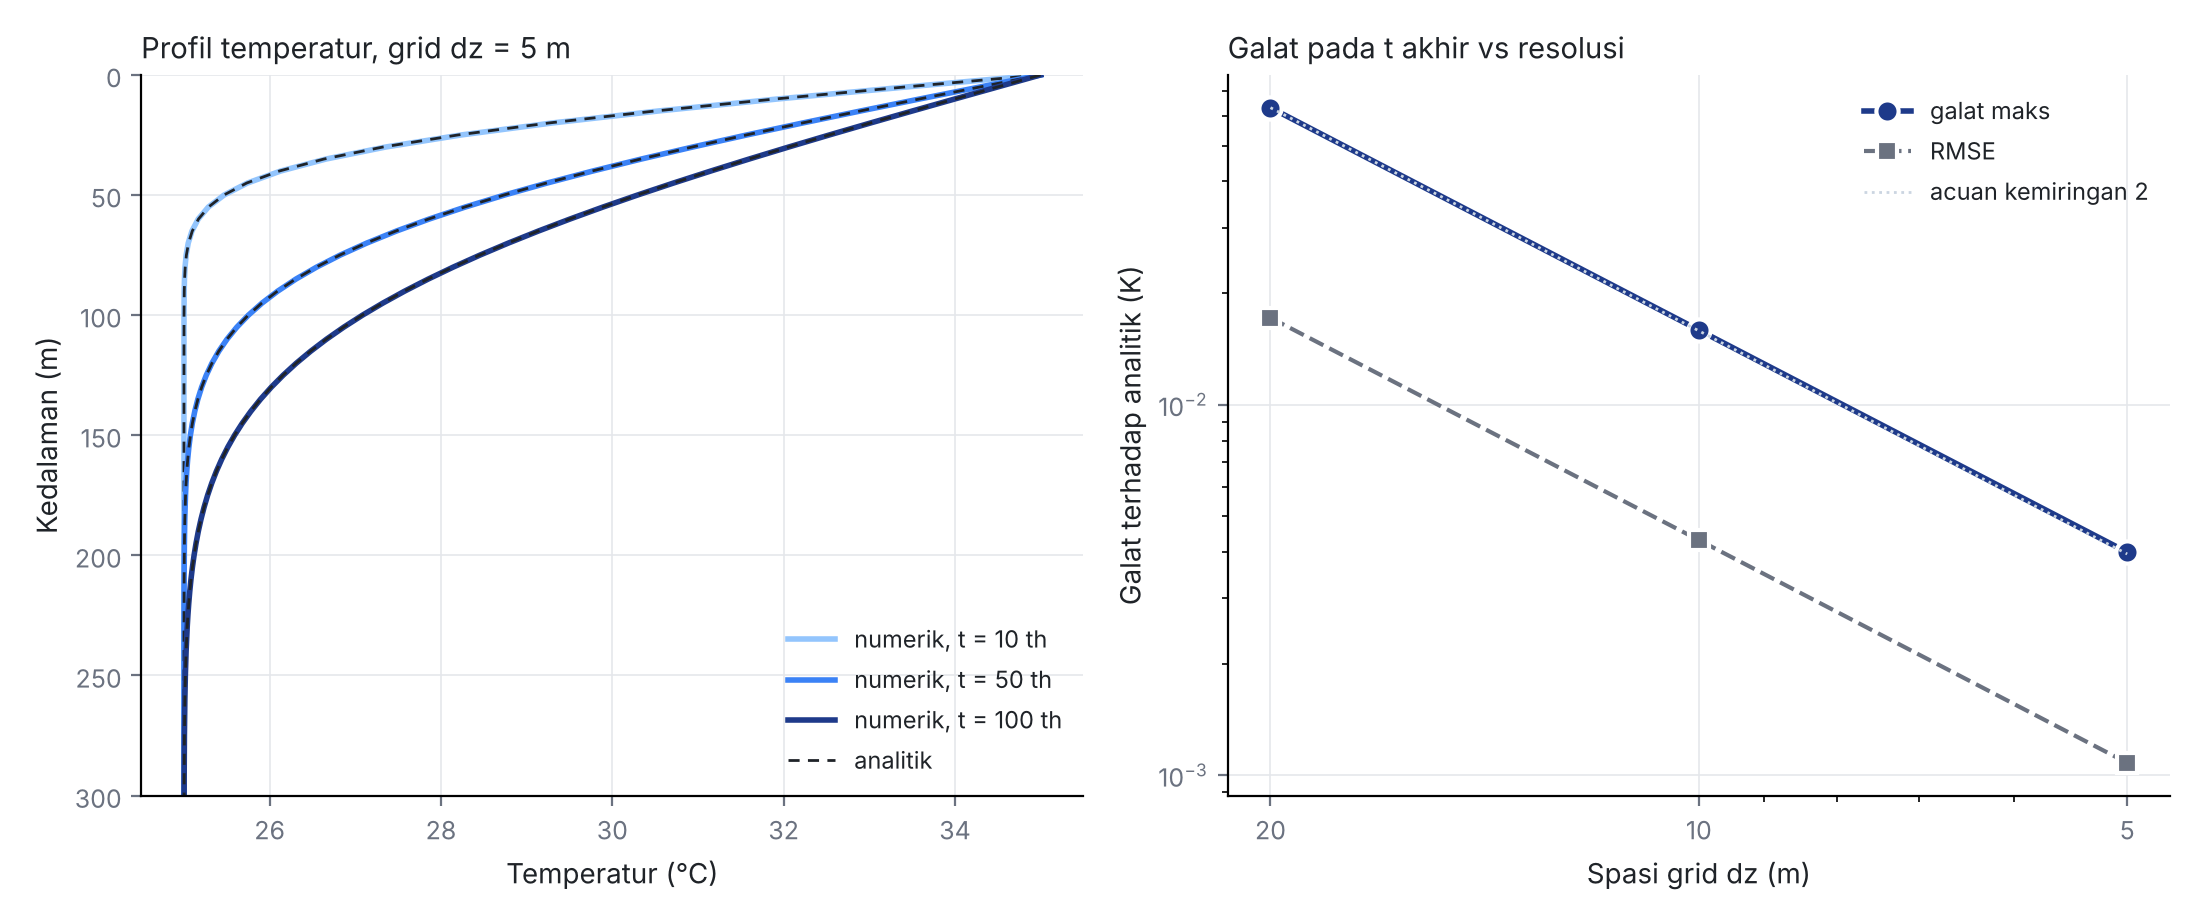

In [7]:
from IPython.display import Image
Image('figures/modeling/r-mod-001_baseline.png')

### 7.4 Interpretasi, dengan pemisahan observasi, perhitungan, inferensi, dan batasan

* **Observasi.** Pada figure, kurva numerik dan kurva analitik hampir tidak dapat dibedakan pada $t=10,\ 50,\ 100$ tahun, dan front panas bergerak makin dalam seiring waktu.
* **Perhitungan.** Dari solusi analitik, anomali temperatur pada $t=100$ tahun turun di bawah 1% dari loncatan (0,1 K) pada kedalaman sekitar 200 m ($\operatorname{erfc}(x)=0{,}01$ pada $x\approx1{,}82$, dikalikan $2\sqrt{\alpha t}\approx112$ m); ini sekaligus menunjukkan $z_{max}=1000$ m sangat memadai. Galat maks turun dari 6.33e-02 K ($\Delta z=20$ m) menjadi 4.00e-03 K ($\Delta z=5$ m). Setiap kali $\Delta z$ dibagi dua, galat turun sekitar 4 kali; orde amatan 1.99 dan 1.99.
* **Inferensi (terbatas).** Hasil konsisten dengan hipotesis $O(\Delta z^2)$ untuk skema ini pada konfigurasi ini. Karena hanya tiga grid dengan rasio 2, ini adalah **indikasi**, bukan bukti asimtotik.
* **Batasan.** Ini verifikasi terhadap solusi analitik untuk medium homogen. Tidak ada klaim tentang akurasi terhadap data borehole, medium berlapis, atau riwayat temperatur nyata. Toleransi ditetapkan sebelum run (0,5% dari loncatan 10 K untuk galat absolut), tetapi hanya diuji pada satu konfigurasi fisis ($\alpha$, $t_{end}$, $\Delta T$ tunggal); perilaku pada parameter lain belum diverifikasi.

---

## 8. Run Gagal Didokumentasikan (bukan dihapus)

Bab 2.4.3 melarang menghapus *failed run* agar workflow tampak bersih. Dua run berikut sengaja dibuat gagal untuk membuktikan bahwa guard dan check **benar-benar dapat gagal**.

### 8.1 Guard-trip: $r_{target}=0{,}6$, guard aktif

Hasil yang diharapkan: berhenti dengan exit code 2 dan tidak ada output ilmiah. Hasil nyata ada di sel berikut, dan failure record ada di `results/run-records/r-mod-001-guard-trip.json`.

In [8]:
!python code/recipes/modeling/r-mod-001.py --config configurations/r-mod-001-guard.json; echo "exit code: $?"

[GUARD] dz=10.0 m: r = alpha*dt/dz^2 = 0.526 > 0.5 (syarat stabilitas FTCS). Run dihentikan.
Failure record: results/run-records/r-mod-001-guard-trip.json
exit code: 2


Catatan: grid pertama ($\Delta z=20$ m) lolos, tetapi guard menghentikan run pada $\Delta z=10$ m karena pembulatan jumlah langkah ke kelipatan 10 menghasilkan $r=0{,}526$. Guard memeriksa $r$ **aktual**, bukan hanya $r_{target}$.

### 8.2 Kontrol negatif: $r_{target}=0{,}6$, guard dilewati

Tujuannya hanya memperlihatkan konsekuensi melanggar syarat stabilitas. Hasilnya disimpan di `results/failed-runs/` dan **tidak boleh dipromosikan**.

In [9]:
!python code/recipes/modeling/r-mod-001.py --config configurations/r-mod-001-negative.json

R-MOD-001 [negative-control] -> Executed as negative control (checks fail as expected)
  dz= 20.0 m  steps=    20  r=0.394  max_err=6.325e-02 K  rmse=1.715e-02 K  order=-
  dz= 10.0 m  steps=    60  r=0.526  max_err=7.901e+00 K  rmse=2.378e+00 K  order=-6.96
  dz=  5.0 m  steps=   220  r=0.574  max_err=3.154e+22 K  rmse=9.129e+21 K  order=-71.76
  [FAIL] stability: r <= 0.5 pada semua grid: 0.5737745454545454  (kriteria <= 0.5)
  [PASS] semua nilai finite: True  (kriteria True)
  [PASS] domain cukup dalam: kebocoran batas bawah (K): 2.479726291715071e-35  (kriteria <= 1e-06)
  [FAIL] maximum principle: T dalam [T_initial, T_surface]: [-3.1382773744234287e+22, 3.1541364661220895e+22]  (kriteria [25.0, 35.0] +/- 1e-09)
  [FAIL] galat maks menurun monoton saat grid dihaluskan: [0.06325296129672253, 7.901379397606799, 3.1541364661220895e+22]  (kriteria strictly decreasing)
  [FAIL] galat maks grid terhalus (K): 3.1541364661220895e+22  (kriteria <= 0.05)
  [FAIL] orde amatan (grid terhalus,

**Observasi:** pada $r=0{,}526$ galat maks melonjak ke 7.90e+00 K, dan pada $r=0{,}574$ menjadi 3.15e+22 K (jauh di luar rentang fisis 25-35 °C). Check stabilitas, maximum principle, monotonisitas, galat absolut, orde, dan integral semuanya **gagal**, sementara check finite dan domain tetap lulus. Artinya rangkaian check tidak "selalu hijau" dan mampu membedakan run benar dari run salah.

---

## 9. Status Evidence dan Identitas Artifact

| Item | Nilai |
| :--- | :--- |
| Status | **Executed - all checks passed** |
| Exit code | `0` |
| Waktu run (UTC, jam sistem sandbox) | `2026-10-20T23:42:18+00:00` |
| Lingkungan | Python 3.13.16, NumPy 2.5.3, SciPy 1.18.1, Matplotlib 3.11.2 |
| Run record | `results/run-records/r-mod-001-baseline.json` |

| Artifact | SHA-256 (12 karakter awal) |
| :--- | :--- |
| `configurations/r-mod-001.json` | `035ef1c6c31b…` |
| `code/recipes/modeling/r-mod-001.py` | `2d4c07f82bb3…` |
| `results/modeling/r-mod-001/baseline/convergence.csv` | `25d86158233c…` |
| `results/modeling/r-mod-001/baseline/profiles_dz5m.csv` | `6aace5159bad…` |
| `figures/modeling/r-mod-001_baseline.png` | `0907db56add4…` |
| `results/modeling/r-mod-001/baseline/summary.json` | `01b0c2d0c611…` |

**Rerun di direktori bersih:** kode dan konfigurasi disalin ke direktori kosong, dijalankan ulang, dan SHA-256 keempat output (`convergence.csv`, `profiles_dz5m.csv`, `summary.json`, PNG) **identik** dengan run pertama. Solver deterministik (tanpa bilangan acak).

**Label yang tidak diklaim:** *calibrated*, *validated against field data*, *converged to a continuum solution*. Yang ditunjukkan hanyalah konsistensi dengan solusi analitik pada tiga grid.

---

### Isi lengkap run record (supaya notebook ini berdiri sendiri sebagai satu file)

Keluaran berikut adalah isi asli `results/run-records/r-mod-001-baseline.json` dan failure record guard-trip dari run nyata di atas.

In [10]:
!cat results/run-records/r-mod-001-baseline.json

{
  "recipe_id": "R-MOD-001",
  "prompt_id": "P-MOD-001",
  "equation_id": "E-HEAT-001",
  "run_name": "baseline",
  "run_kind": "baseline",
  "command": "python3 code/recipes/modeling/r-mod-001.py --config configurations/r-mod-001.json",
  "timestamp_utc": "2026-10-20T23:42:18+00:00",
  "environment": {
    "python": "3.13.16",
    "numpy": "2.5.3",
    "scipy": "1.18.1",
    "matplotlib": "3.11.2",
    "platform": "Linux-6.18.44-fc-v139-x86_64-with-glibc2.39"
  },
  "inputs": {
    "config": "configurations/r-mod-001.json",
    "config_sha256": "035ef1c6c31b7c7927bc765bc34c12120d08f37f4187d4ca41934d99cac1b067"
  },
  "code_sha256": "2d4c07f82bb36f582560e2026c5fa46b71a6ecfdd8c4b165cd0db46b4ae73e83",
  "status": "Executed - all checks passed",
  "exit_code": 0,
  "checks_all_passed": true,
  "checks": [
    {
      "name": "stability: r <= 0.5 pada semua grid",
      "value": 0.39446999999999993,
      "threshold": "<= 0.5",
      "passed": true
    },
    {
      "name": "semua nilai 

In [11]:
!cat results/run-records/r-mod-001-guard-trip.json

{
  "recipe_id": "R-MOD-001",
  "prompt_id": "P-MOD-001",
  "equation_id": "E-HEAT-001",
  "run_name": "guard-trip",
  "run_kind": "baseline",
  "command": "python3 code/recipes/modeling/r-mod-001.py --config configurations/r-mod-001-guard.json",
  "timestamp_utc": "2026-10-20T23:42:19+00:00",
  "environment": {
    "python": "3.13.16",
    "numpy": "2.5.3",
    "scipy": "1.18.1",
    "matplotlib": "3.11.2",
    "platform": "Linux-6.18.44-fc-v139-x86_64-with-glibc2.39"
  },
  "inputs": {
    "config": "configurations/r-mod-001-guard.json",
    "config_sha256": "ce175752ff27de3ea6740ba73776f5012cf6bedf56d742dd4e480d89449b5d06"
  },
  "code_sha256": "2d4c07f82bb36f582560e2026c5fa46b71a6ecfdd8c4b165cd0db46b4ae73e83",
  "status": "Stopped by stability guard (no output promoted)",
  "exit_code": 2,
  "failure_reason": "dz=10.0 m: r = alpha*dt/dz^2 = 0.526 > 0.5 (syarat stabilitas FTCS). Run dihentikan.",
  "outputs": {}
}


### Isi run record `results/run-records/r-mod-001-baseline.json` (disalin utuh agar notebook ini berdiri sendiri)

```json
{
  "recipe_id": "R-MOD-001",
  "prompt_id": "P-MOD-001",
  "equation_id": "E-HEAT-001",
  "run_name": "baseline",
  "run_kind": "baseline",
  "command": "python3 code/recipes/modeling/r-mod-001.py --config configurations/r-mod-001.json",
  "timestamp_utc": "2026-10-20T23:42:18+00:00",
  "environment": {
    "python": "3.13.16",
    "numpy": "2.5.3",
    "scipy": "1.18.1",
    "matplotlib": "3.11.2",
    "platform": "Linux-6.18.44-fc-v139-x86_64-with-glibc2.39"
  },
  "inputs": {
    "config": "configurations/r-mod-001.json",
    "config_sha256": "035ef1c6c31b7c7927bc765bc34c12120d08f37f4187d4ca41934d99cac1b067"
  },
  "code_sha256": "2d4c07f82bb36f582560e2026c5fa46b71a6ecfdd8c4b165cd0db46b4ae73e83",
  "status": "Executed - all checks passed",
  "exit_code": 0,
  "checks_all_passed": true,
  "checks": [
    {
      "name": "stability: r <= 0.5 pada semua grid",
      "value": 0.39446999999999993,
      "threshold": "<= 0.5",
      "passed": true
    },
    {
      "name": "semua nilai finite",
      "value": true,
      "threshold": "True",
      "passed": true
    },
    {
      "name": "domain cukup dalam: kebocoran batas bawah (K)",
      "value": 2.479726291715071e-35,
      "threshold": "<= 1e-06",
      "passed": true
    },
    {
      "name": "maximum principle: T dalam [T_initial, T_surface]",
      "value": [
        25.0,
        35.0
      ],
      "threshold": "[25.0, 35.0] +/- 1e-09",
      "passed": true
    },
    {
      "name": "galat maks menurun monoton saat grid dihaluskan",
      "value": [
        0.06325296129672253,
        0.01589017772257506,
        0.0039966703136258275
      ],
      "threshold": "strictly decreasing",
      "passed": true
    },
    {
      "name": "galat maks grid terhalus (K)",
      "value": 0.0039966703136258275,
      "threshold": "<= 0.05",
      "passed": true
    },
    {
      "name": "orde amatan (grid terhalus, norma maks)",
      "value": 1.991264786007973,
      "threshold": ">= 1.0",
      "passed": true
    },
    {
      "name": "integral anomali panas: galat relatif grid terhalus",
      "value": 0.0008853702741696703,
      "threshold": "<= 0.01",
      "passed": true
    }
  ],
  "outputs": {
    "results/modeling/r-mod-001/baseline/convergence.csv": "25d86158233c012dfd15c1c554d01b642fa0ebb2ef012c0a1a2045bc2b89ec97",
    "results/modeling/r-mod-001/baseline/profiles_dz5m.csv": "6aace5159bad32eda59aada521a755423f2d9a577de60aa9e5cc395fe5682065",
    "figures/modeling/r-mod-001_baseline.png": "0907db56add48c81921457b0c4670d4de133cc23cda425afe3f882275e1eb29e",
    "results/modeling/r-mod-001/baseline/summary.json": "01b0c2d0c611c1ce7e5a964f8041e1975926b48f051e1203f4f816fcb137874c"
  }
}
```

---

## 10. Pemetaan ke Tahapan Pembuatan Recipe (Bab 2.4.1)

| Tahap 2.4.1 | Di recipe ini |
| :--- | :--- |
| 1. Problem dan batas keputusan | Bagian 1 (satu outcome: verifikasi solver; inversi dipisah) |
| 2. Minimal theory dan asumsi | Bagian 2 (persamaan, BC/IC, stabilitas, asumsi, hipotesis orde) |
| 3. Input dan constraint contract | Bagian 3 + file konfigurasi |
| 4. Prompt dan mekanisme terkecil | Bagian 4; hanya Python lokal, tanpa plugin/MCP/jaringan |
| 5. Implementasi sebagai artifact | Bagian 5; kode, konfigurasi, dan output terpisah |
| 6. Output dan check sebelum run | Bagian 6; toleransi ditulis sebelum run |
| 7. Jalankan, catat status, revisi | Bagian 7-9; run record, hash, failed run |

## 11. Tindakan Lanjutan (*Next Action*)

1. **R-MOD-002 (usulan, belum dikerjakan):** skema implisit Crank-Nicolson dan perbandingannya dengan FTCS (biaya vs akurasi pada $r>0{,}5$).
2. **R-MOD-003 (usulan, belum dikerjakan):** medium dua lapis dengan $\alpha$ berbeda; solusi analitik tidak tersedia sehingga pembanding berpindah ke grid sangat halus.
3. Recipe inversi riwayat temperatur permukaan hanya setelah data borehole yang diizinkan tersedia, dengan provenance dan unit yang tercatat.